The three ODE solvers which will be used are Runge-Kutta 45 (RK45) which is a standard explicit solver, Radau, which is an implicit Runge-Kutta solver, and LSODA, which is an adaptive solver which in addition to having adaptive timesteps also switches between the non-stiff Adams method and the stiff BDF method depending on how fast the stiffness it detects.

In [71]:
import time

from matplotlib import pyplot as plt
import numpy as np
import pandas as pd
from scipy.integrate import solve_ivp 

runtimes = []
nsteps = []
errors = []
nfevOverSteps = []


# Lotka-Volterra
def lotka_volterra(t,y,a,b,c,d):
    R,F = y

    dRdt = a*R-b*F*R
    dFdt = c*R*F-d*F

    return [dRdt, dFdt]

a = 0.4
b = 0.001
c = 0.001
d = 0.9

# Initial conditions
y0 = [600, 400]

# Time interval
t_LV = [0, 30]

# RK45
t_eval = np.linspace(t[0],t[1],1000)
tStart = time.perf_counter() 
sol = solve_ivp(
    fun=lotka_volterra,
    t_span=t_LV,
    y0=y0,
    method='RK45',
    args=(a,b,c,d),
    #t_eval=t_eval,
    dense_output=True
)
tEnd = time.perf_counter()
y_LV_RK45 = sol.sol

tSolv_RK45 = tEnd-tStart
steps_RK45 =  len(sol.t)
error_RK45 = 0 # IDK how to interpret
nfevOverSteps_RK45 = sol.nfev/len(sol.t)
print("Solver time: ",tSolv_RK45, "s")
print("Number of time steps taken: ", len(sol.t))
print("Accuracy: Idk")
print("nfev/timesteps: ",sol.nfev/len(sol.t))


# Radau
tStart = time.perf_counter() 
sol = solve_ivp(
    fun=lotka_volterra,
    t_span=t,
    y0=y0,
    method='Radau',
    args=(a,b,c,d),
    #t_eval=t_eval,
    dense_output=True
)
tEnd = time.perf_counter()
y_LV_Radau = sol.sol

tSolv_Radau = tEnd-tStart
steps_Radau =  len(sol.t)
error_Radau = 0 # IDK how to interpret
nfevOverSteps_Radau = sol.nfev/len(sol.t)
print("Solver time: ",tSolv_Radau, "s")
print("Number of time steps taken: ", len(sol.t))
print("Accuracy: Idk")
print("nfev/timesteps: ",sol.nfev/len(sol.t))

# LSODA
tStart = time.perf_counter() 
sol = solve_ivp(
    fun=lotka_volterra,
    t_span=t_LV,
    y0=y0,
    method='LSODA',
    args=(a,b,c,d),
    #t_eval=t_eval,
    dense_output=True
)
tEnd = time.perf_counter()
y_LV_LSODA = sol.sol

tSolv_LSODA = tEnd-tStart
steps_LSODA =  len(sol.t)
error_LSODA = 0 # IDK how to interpret
nfevOverSteps_LSODA = sol.nfev/len(sol.t)
print("Solver time: ",tSolv_LSODA, "s")
print("Number of time steps taken: ", len(sol.t))
print("Accuracy: Idk")
print("nfev/timesteps: ",sol.nfev/len(sol.t),"\n")

# For table
data = {
    "Solver": ["RK45", "Radau", "LSODA"],
    "Runtime [s]": [tSolv_RK45, tSolv_Radau, tSolv_LSODA],
    "Steps": [steps_RK45, steps_Radau, steps_LSODA],
    "Error": [error_RK45, error_Radau, error_LSODA],
    "nfev/step": [nfevOverSteps_RK45, nfevOverSteps_Radau, nfevOverSteps_LSODA]
}

df = pd.DataFrame(data)

print(df.to_string(index=False))

Solver time:  0.015191599959507585 s
Number of time steps taken:  19
Accuracy: Idk
nfev/timesteps:  7.052631578947368
Solver time:  0.0465011999476701 s
Number of time steps taken:  25
Accuracy: Idk
nfev/timesteps:  8.96
Solver time:  0.016276800073683262 s
Number of time steps taken:  61
Accuracy: Idk
nfev/timesteps:  2.2131147540983607 

Solver  Runtime [s]  Steps  Error  nfev/step
  RK45     0.015192     19      0   7.052632
 Radau     0.046501     25      0   8.960000
 LSODA     0.016277     61      0   2.213115


RK45 and LSODA seem to be similar in speed for and # of function evaluations per step. Radau slower and makes more calculations per step.

In [72]:
def Belousov_Zhabotinsky(t, y, alpha, beta, gamma):
    x1,x2,x3 = y

    dx1dt = alpha*(x2+x1*(1-beta*x1-x2))
    dx2dt = 1/alpha*(x3-(1+x1)*x2)
    dx3dt = gamma*(x1-x3)

    return [dx1dt, dx2dt, dx3dt]

# Time interval
t_BZ = [0, 20]

# Initial conditions
y0 = [1, 2, 3]

# Constants
alpha = 77.27
beta = 8.375*10**(-6)
gamma = 1.161

t_eval = np.linspace(t[0], t_BZ[1], 1000)

# RK45

tStart = time.perf_counter()
sol = solve_ivp(
    fun = Belousov_Zhabotinsky,
    t_span = t_BZ,
    y0 = y0,
    #t_eval = t_eval,
    args=(alpha, beta, gamma),
    method="RK45",
    dense_output=True
)
tEnd = time.perf_counter()
y_BZ_RK45 = sol.sol

tSolv_RK45 = tEnd-tStart
steps_RK45 =  len(sol.t)
error_RK45 = 0 # IDK how to interpret
nfevOverSteps_RK45 = sol.nfev/len(sol.t)
print("Solver time: ",tSolv_RK45, "s")
print("Number of time steps taken: ", len(sol.t))
print("Accuracy: Idk")
print("nfev/timesteps: ",sol.nfev/len(sol.t))


# Radau

tStart = time.perf_counter()
sol = solve_ivp(
    fun = Belousov_Zhabotinsky,
    t_span = t_BZ,
    y0 = y0,
    #t_eval = t_eval,
    args=(alpha, beta, gamma),
    method="Radau",
    dense_output=True
)
tEnd = time.perf_counter()
y_BZ_Radau = sol.sol

tSolv_Radau = tEnd-tStart
steps_Radau =  len(sol.t)
error_Radau = 0 # IDK how to interpret
nfevOverSteps_Radau = sol.nfev/len(sol.t)
print("Solver time: ",tSolv_Radau, "s")
print("Number of time steps taken: ", len(sol.t))
print("Accuracy: Idk")
print("nfev/timesteps: ",sol.nfev/len(sol.t))


# LSODA

tStart = time.perf_counter()
sol = solve_ivp(
    fun = Belousov_Zhabotinsky,
    t_span = t_BZ,
    y0 = y0,
    #t_eval = t_eval,
    args=(alpha, beta, gamma),
    method="LSODA",
    dense_output=True
)
tEnd = time.perf_counter()
y_BZ_LSODA = sol.sol

tSolv_LSODA = tEnd-tStart
steps_LSODA =  len(sol.t)
error_LSODA = 0 # IDK how to interpret
nfevOverSteps_LSODA = sol.nfev/len(sol.t)
print("Solver time: ",tSolv_LSODA, "s")
print("Number of time steps taken: ", len(sol.t))
print("Accuracy: Idk")
print("nfev/timesteps: ",sol.nfev/len(sol.t))


# For table
data = {
    "Solver": ["RK45", "Radau", "LSODA"],
    "Runtime [s]": [tSolv_RK45, tSolv_Radau, tSolv_LSODA],
    "Steps": [steps_RK45, steps_Radau, steps_LSODA],
    "Error": [error_RK45, error_Radau, error_LSODA],
    "nfev/step": [nfevOverSteps_RK45, nfevOverSteps_Radau, nfevOverSteps_LSODA]
}

df = pd.DataFrame(data)

print(df.to_string(index=False))

Solver time:  0.05927910003811121 s
Number of time steps taken:  265
Accuracy: Idk
nfev/timesteps:  6.59622641509434
Solver time:  0.02214090002235025 s
Number of time steps taken:  19
Accuracy: Idk
nfev/timesteps:  9.263157894736842
Solver time:  0.005174099933356047 s
Number of time steps taken:  58
Accuracy: Idk
nfev/timesteps:  2.3793103448275863
Solver  Runtime [s]  Steps  Error  nfev/step
  RK45     0.059279    265      0   6.596226
 Radau     0.022141     19      0   9.263158
 LSODA     0.005174     58      0   2.379310


Huge spike at ~25s. Correct or not?

In [73]:
# Lorenz Chaos

def lorenz(t,y,sigma,rho,beta):
    [x1, x2, x3] = y

    dx1dt = sigma*(x2-x1)
    dx2dt = x1*(rho-x3)-x2
    dx3dt = x1*x2-beta*x3

    return [dx1dt, dx2dt, dx3dt]

# Constants
beta = 8/3
rho = 50
sigma = 10

# Initial conditions
x0 = [-8, 8, 27]

# Time interval
t_Lorenz = [0,20]

# RK45

tStart = time.perf_counter()
sol = solve_ivp(
    fun = lorenz,
    t_span = t,
    y0 = x0,
    args = (sigma, rho, beta),
    method = "RK45",
    dense_output=True
)
tEnd = time.perf_counter()
y_Lorenz_RK45 = sol.sol

tSolv_RK45 = tEnd-tStart
steps_RK45 =  len(sol.t)
error_RK45 = 0 # IDK how to interpret
nfevOverSteps_RK45 = sol.nfev/len(sol.t)
print("Solver time: ",tSolv_RK45, "s")
print("Number of time steps taken: ", len(sol.t))
print("Accuracy: Idk")
print("nfev/timesteps: ",sol.nfev/len(sol.t))


# Radau

tStart = time.perf_counter()
sol = solve_ivp(
    fun = lorenz,
    t_span = t,
    y0 = x0,
    args = (sigma, rho, beta),
    method = "Radau",
    dense_output=True
)
tEnd = time.perf_counter()
y_Lorenz_Radau = sol.sol

tSolv_Radau = tEnd-tStart
steps_Radau =  len(sol.t)
error_Radau = 0 # IDK how to interpret
nfevOverSteps_Radau = sol.nfev/len(sol.t)
print("Solver time: ",tSolv_Radau, "s")
print("Number of time steps taken: ", len(sol.t))
print("Accuracy: Idk")
print("nfev/timesteps: ",sol.nfev/len(sol.t))


# LSODA

tStart = time.perf_counter()
sol = solve_ivp(
    fun = lorenz,
    t_span = t,
    y0 = x0,
    args = (sigma, rho, beta),
    method = "LSODA",
    dense_output=True
)
tEnd = time.perf_counter()
y_Lorenz_LSODA = sol.sol

tSolv_LSODA = tEnd-tStart
steps_LSODA =  len(sol.t)
error_LSODA = 0 # IDK how to interpret
nfevOverSteps_LSODA = sol.nfev/len(sol.t)
print("Solver time: ",tSolv_LSODA, "s")
print("Number of time steps taken: ", len(sol.t))
print("Accuracy: Idk")
print("nfev/timesteps: ",sol.nfev/len(sol.t))


# For table
data = {
    "Solver": ["RK45", "Radau", "LSODA"],
    "Runtime [s]": [tSolv_RK45, tSolv_Radau, tSolv_LSODA],
    "Steps": [steps_RK45, steps_Radau, steps_LSODA],
    "Error": [error_RK45, error_Radau, error_LSODA],
    "nfev/step": [nfevOverSteps_RK45, nfevOverSteps_Radau, nfevOverSteps_LSODA]
}

df = pd.DataFrame(data)

print(df.to_string(index=False))

Solver time:  0.057519500027410686 s
Number of time steps taken:  303
Accuracy: Idk
nfev/timesteps:  8.085808580858085
Solver time:  0.40633280004840344 s
Number of time steps taken:  578
Accuracy: Idk
nfev/timesteps:  8.849480968858131
Solver time:  0.09405060007702559 s
Number of time steps taken:  1458
Accuracy: Idk
nfev/timesteps:  2.0651577503429355
Solver  Runtime [s]  Steps  Error  nfev/step
  RK45     0.057520    303      0   8.085809
 Radau     0.406333    578      0   8.849481
 LSODA     0.094051   1458      0   2.065158


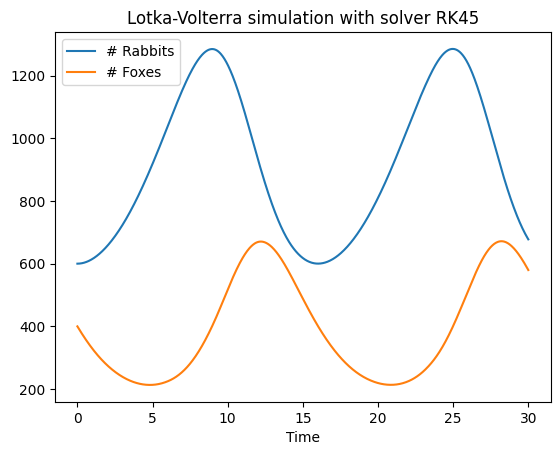

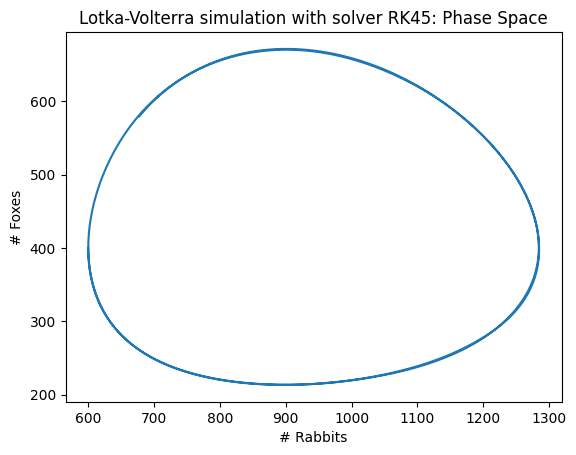

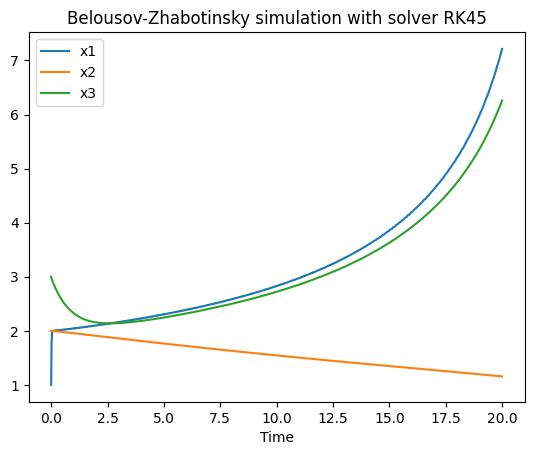

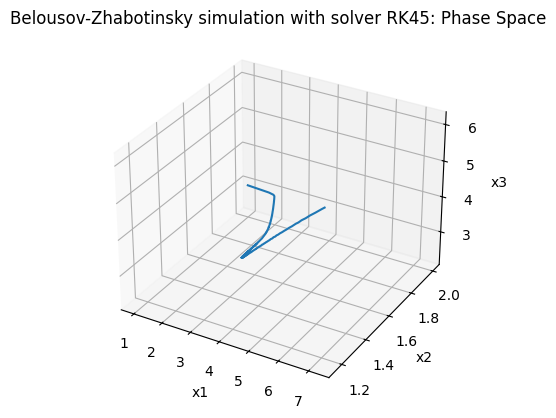

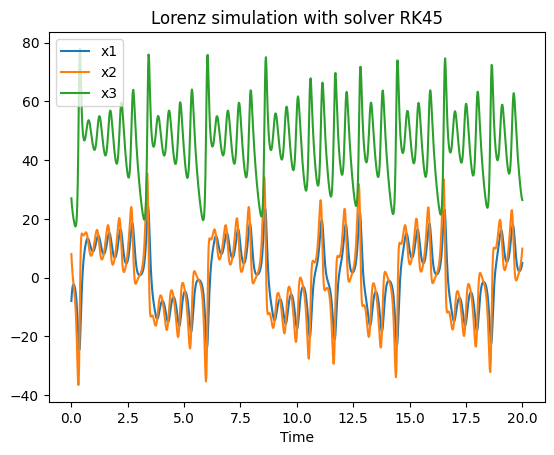

Text(0.5, 0.92, 'Lorenz simulation with solver RK45: Phase Space')

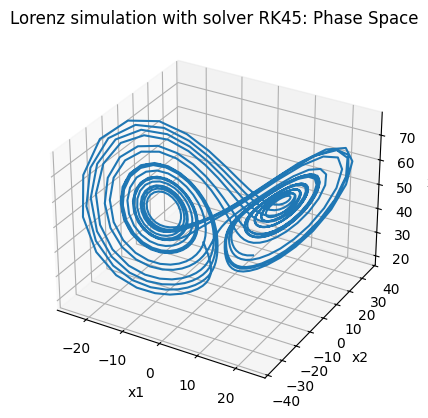

In [74]:
# Lotka-Volterra Plots

# Time Series
t_plot_LV = np.linspace(t_LV[0], t_LV[1], 1000)
y_plot_LV = y_LV_RK45(t_plot) # Choose method here
plt.figure()
plt.title('Lotka-Volterra simulation with solver RK45')
plt.plot(t_plot_LV, y_plot_LV[0,:],label='# Rabbits')
plt.plot(t_plot_LV, y_plot_LV[1,:],label='# Foxes')
plt.xlabel('Time')
plt.legend()
plt.show()

# Phase Diagram
plt.figure()
plt.title("Lotka-Volterra simulation with solver RK45: Phase Space")
plt.xlabel("# Rabbits")
plt.ylabel("# Foxes")
plt.plot(y_plot_LV[0,:], y_plot_LV[1,:])
plt.show()

# Belousov-Zhabotinsky Plots

# Time Series
t_plot_BZ = np.linspace(t_BZ[0], t_BZ[1], 1000)
y_plot_BZ = y_BZ_RK45(t_plot_BZ)

plt.figure()
plt.title('Belousov-Zhabotinsky simulation with solver RK45')
plt.plot(t_plot_BZ, y_plot_BZ[0,:],label='x1')
plt.plot(t_plot_BZ, y_plot_BZ[1,:],label='x2')
plt.plot(t_plot_BZ, y_plot_BZ[2,:],label='x3')
plt.xlabel('Time')
plt.legend()
plt.show()

# Phase Diagram
fig = plt.figure()
ax = fig.add_subplot(111, projection="3d")

ax.plot(
    y_plot_BZ[0,:],
    y_plot_BZ[1,:],
    y_plot_BZ[2,:]
)
ax.set_xlabel('x1')
ax.set_ylabel('x2')
ax.set_zlabel('x3')
ax.set_title("Belousov-Zhabotinsky simulation with solver RK45: Phase Space")


# Lorenz Plots

# Time Series
t_plot_Lorenz = np.linspace(t_BZ[0], t_BZ[1], 1000)
y_plot_Lorenz = y_Lorenz_RK45(t_plot_Lorenz)

plt.figure()
plt.title('Lorenz simulation with solver RK45')
plt.plot(t_plot_Lorenz, y_plot_Lorenz[0,:],label='x1')
plt.plot(t_plot_Lorenz, y_plot_Lorenz[1,:],label='x2')
plt.plot(t_plot_Lorenz, y_plot_Lorenz[2,:],label='x3')
plt.xlabel('Time')
plt.legend()
plt.show()

# Phase Diagram
fig = plt.figure()
ax = fig.add_subplot(111, projection="3d")

ax.plot(
    y_plot_Lorenz[0,:],
    y_plot_Lorenz[1,:],
    y_plot_Lorenz[2,:]
)
ax.set_xlabel('x1')
ax.set_ylabel('x2')
ax.set_zlabel('x3')
ax.set_title("Lorenz simulation with solver RK45: Phase Space")
